# Netflix Data Analysis: Global Expansion Strategy

**Course:** ITI 545 | **Team:** Team 06 | **Challenge chosen:** Challenge 2 - Global Expansion Strategy

## Business question
> Which countries contribute the most content to Netflix, and where could Netflix expand next?

## Approach
1. Load and inspect the Netflix catalog dataset.
2. Clean the data (duplicates, inconsistent labels, missing values).
3. Run exploratory data analysis (EDA) by country.
4. Visualize content volume, quality and content mix per country.
5. Derive business insights and an expansion recommendation.

**Note on data size:** the catalog file contains only 40 rows, so every result describes this sample and should be treated as directional, not as a statement about Netflix's full library.

## 1. Setup
Import the libraries and define the constants used throughout the notebook, so that thresholds are easy to find and change.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# File location (keep the CSV in the same folder as this notebook)
DATA_PATH = "netflix_catalog.csv"

# Thresholds used in the expansion analysis
LOW_VOLUME_MAX_TITLES = 3     # a country with this many titles or fewer counts as "low volume"
MIN_RATED_TITLES = 2          # need at least this many rated titles to trust a country's average rating

# Consistent colour palette (Netflix-inspired)
NETFLIX_RED = "#E50914"
DARK_GREY = "#221F1F"
LIGHT_GREY = "#B3B3B3"

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

## 2. Load and inspect the data

In [2]:
netflix_raw = pd.read_csv(DATA_PATH)

print("Shape (rows, columns):", netflix_raw.shape)
print()
print(netflix_raw.head(8).to_string(index=False))

Shape (rows, columns): (40, 9)

show_id           title    type           genre        country  release_year  rating  seasons  duration_min
  tt001 Stranger Things TV Show          Sci-Fi  United States          2016     8.7      4.0           NaN
  tt002            Dark TV Show        Thriller        Germany          2017     8.8      3.0           NaN
  tt003          Narcos TV Show           Crime  United States          2015     8.8      3.0           NaN
  tt004       The Crown TV Show           Drama United Kingdom          2016     8.6      6.0           NaN
  tt005     Money Heist TV Show           Crime          Spain          2017     8.2      5.0           NaN
  tt006      Squid Game TV Show        Thriller    South Korea          2021     8.0      2.0           NaN
  tt007    Black Mirror TV Show Science Fiction United Kingdom          2011     8.7      6.0           NaN
  tt008           Ozark TV Show           Crime  United States          2017     8.5      4.0           

In [3]:
print("Column data types:")
print(netflix_raw.dtypes.to_string())
print()
print("Missing values per column:")
print(netflix_raw.isna().sum().to_string())
print()
print("Number of fully duplicated rows:", netflix_raw.duplicated().sum())
print("Number of repeated title + release year pairs:", netflix_raw.duplicated(subset=["title", "release_year"]).sum())
print()
print("Genre labels found:", sorted(netflix_raw["genre"].dropna().unique()))

Column data types:
show_id             str
title               str
type                str
genre               str
country             str
release_year      int64
rating          float64
seasons         float64
duration_min    float64

Missing values per column:
show_id          0
title            0
type             0
genre            1
country          2
release_year     0
rating           2
seasons         17
duration_min    25

Number of fully duplicated rows: 0
Number of repeated title + release year pairs: 1

Genre labels found: ['Action', 'Adventure', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Mystery', 'Romance', 'Sci-Fi', 'Science Fiction', 'Thriller', 'War']


**What the inspection shows**

- The dataset has 40 titles and 9 columns: ID, title, type, genre, country, release year, rating, seasons and duration.
- `seasons` is only filled for TV shows and `duration_min` only for movies, so most of their missing values are expected, not errors.
- `country`, `genre` and `rating` have a few genuine gaps.
- "Dark" appears twice under different IDs (same title and year), so it is a duplicate record.
- The genre labels `Sci-Fi` and `Science Fiction` mean the same thing and must be unified.
- One row ("Unknown Title") has no genre, country or rating and carries no information.

## 3. Data cleaning
Each step is applied to a copy of the raw data, and the number of rows is printed so the effect is visible.

In [4]:
netflix = netflix_raw.copy()

# Step 1: remove text whitespace issues in the text columns
text_columns = ["title", "type", "genre", "country"]
for column in text_columns:
    netflix[column] = netflix[column].str.strip()

# Step 2: drop placeholder rows that have no genre, country AND rating
is_placeholder = netflix[["genre", "country", "rating"]].isna().all(axis=1)
print("Placeholder rows removed:", is_placeholder.sum(), "->", netflix.loc[is_placeholder, "title"].tolist())
netflix = netflix[~is_placeholder]

# Step 3: drop duplicated titles (same title and release year), keeping the first record
rows_before = len(netflix)
netflix = netflix.drop_duplicates(subset=["title", "release_year"], keep="first")
print("Duplicate records removed:", rows_before - len(netflix))

# Step 4: unify inconsistent genre labels
netflix["genre"] = netflix["genre"].replace({"Science Fiction": "Sci-Fi"})

# Step 5: missing country is labelled "Unknown" (we do not guess it) and excluded from country analysis later
netflix["country"] = netflix["country"].fillna("Unknown")

print()
print("Rows after cleaning:", len(netflix))
print()
print("Remaining missing values:")
print(netflix.isna().sum().to_string())

Placeholder rows removed: 1 -> ['Unknown Title']
Duplicate records removed: 1

Rows after cleaning: 38

Remaining missing values:
show_id          0
title            0
type             0
genre            0
country          0
release_year     0
rating           1
seasons         16
duration_min    23


**Cleaning decisions**

- **Placeholder row removed:** "Unknown Title" had nothing usable.
- **Duplicate removed:** the second "Dark" record was dropped.
- **Genre labels unified:** `Science Fiction` became `Sci-Fi`.
- **Missing country kept as "Unknown":** the country is not in the data, so we do not guess it. The title is excluded from the country analysis only.
- **Missing rating left empty:** one title has no rating. It is counted in volume but ignored in average ratings, instead of inventing a value.
- **`seasons` and `duration_min` left empty:** they are missing by design (TV shows have no duration, movies have no seasons).

## 4. Exploratory data analysis (EDA)
### 4.1 Overall catalog profile

In [5]:
print("Titles by type:")
print(netflix["type"].value_counts().to_string())
print()
print("Release years covered:", netflix["release_year"].min(), "to", netflix["release_year"].max())
print("Average rating (all rated titles):", round(netflix["rating"].mean(), 2))
print()
print("Average rating by type:")
print(netflix.groupby("type")["rating"].mean().round(2).to_string())

Titles by type:
type
TV Show    23
Movie      15

Release years covered: 2011 to 2022
Average rating (all rated titles): 7.83

Average rating by type:
type
Movie      7.02
TV Show    8.32


### 4.2 Content volume by country
Titles with an unknown country are excluded here, because they cannot be assigned to a market.

In [6]:
titles_with_country = netflix[netflix["country"] != "Unknown"]

country_summary = (
    titles_with_country
    .groupby("country")
    .agg(
        total_titles=("title", "count"),
        rated_titles=("rating", "count"),
        average_rating=("rating", "mean"),
    )
    .sort_values("total_titles", ascending=False)
)
country_summary["share_of_titles_pct"] = country_summary["total_titles"] / country_summary["total_titles"].sum() * 100

print("Titles with a known country:", len(titles_with_country))
print("Number of countries:", len(country_summary))
print()
print(country_summary.round(2).to_string())

Titles with a known country: 37
Number of countries: 9

                total_titles  rated_titles  average_rating  share_of_titles_pct
country                                                                        
United States             18            18            7.64                48.65
United Kingdom             6             6            8.13                16.22
India                      3             2            8.50                 8.11
Spain                      3             3            7.53                 8.11
Germany                    2             2            8.30                 5.41
South Korea                2             2            7.65                 5.41
France                     1             1            7.50                 2.70
Poland                     1             1            8.00                 2.70
Mexico                     1             1            7.70                 2.70


In [7]:
top_two_share = country_summary["share_of_titles_pct"].head(2).sum()
print(f"Top country: {country_summary.index[0]} with {country_summary['share_of_titles_pct'].iloc[0]:.1f}% of titles")
print(f"Top two countries together: {top_two_share:.1f}% of titles")

Top country: United States with 48.6% of titles
Top two countries together: 64.9% of titles


### 4.3 Content mix and quality: US vs rest of world

In [8]:
content_mix = pd.crosstab(titles_with_country["country"], titles_with_country["type"])
content_mix = content_mix.loc[country_summary.index]
print("Titles by country and type:")
print(content_mix.to_string())

is_us = titles_with_country["country"] == "United States"
average_rating_us = titles_with_country.loc[is_us, "rating"].mean()
average_rating_non_us = titles_with_country.loc[~is_us, "rating"].mean()
print()
print(f"Average rating, United States titles : {average_rating_us:.2f}")
print(f"Average rating, non-US titles        : {average_rating_non_us:.2f}")
print(f"Difference                           : {average_rating_non_us - average_rating_us:+.2f}")

Titles by country and type:
type            Movie  TV Show
country                       
United States       9        9
United Kingdom      1        5
India               1        2
Spain               1        2
Germany             1        1
South Korea         1        1
France              0        1
Poland              0        1
Mexico              1        0

Average rating, United States titles : 7.64
Average rating, non-US titles        : 7.97
Difference                           : +0.33


## 5. Visualizations
### 5.1 Which countries contribute the most titles?

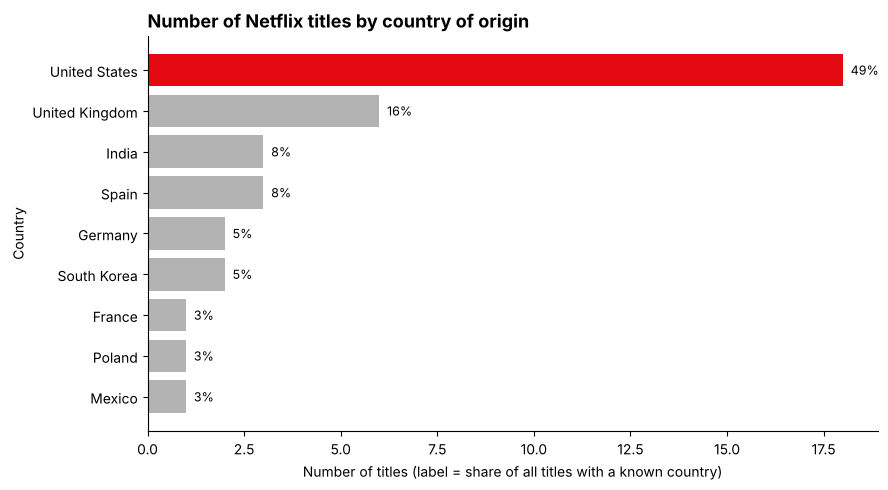

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = [NETFLIX_RED if country == country_summary.index[0] else LIGHT_GREY for country in country_summary.index]
bars = ax.barh(country_summary.index[::-1], country_summary["total_titles"][::-1], color=bar_colors[::-1])

for bar, share in zip(bars, country_summary["share_of_titles_pct"][::-1]):
    ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height() / 2, f"{share:.0f}%", va="center", fontsize=9)

ax.set_title("Number of Netflix titles by country of origin", fontsize=13, weight="bold", loc="left")
ax.set_xlabel("Number of titles (label = share of all titles with a known country)")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

The United States dominates the catalog, followed by the United Kingdom. All other countries contribute only one to three titles each.

### 5.2 Which countries have the best-rated content?
Only countries with at least two rated titles are shown, so a single title cannot decide a country's score.

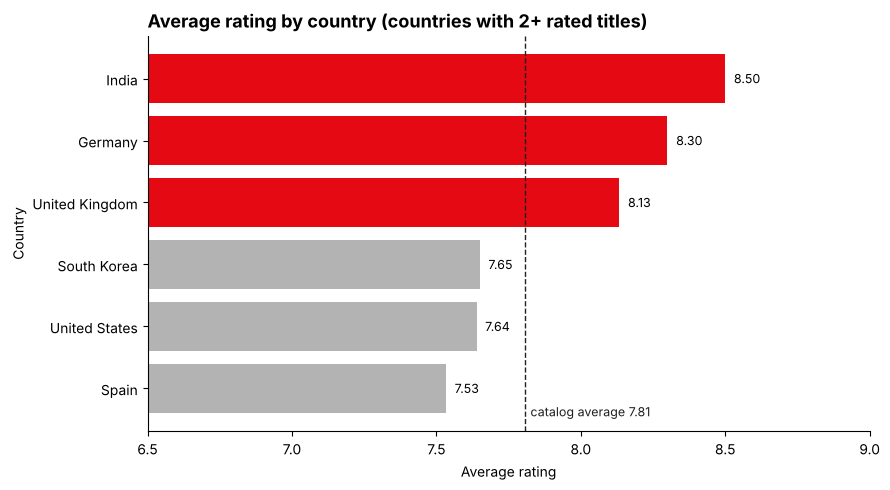

In [10]:
rating_view = country_summary[country_summary["rated_titles"] >= MIN_RATED_TITLES].sort_values("average_rating")
overall_average_rating = titles_with_country["rating"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
bar_colors = [NETFLIX_RED if value >= overall_average_rating else LIGHT_GREY for value in rating_view["average_rating"]]
ax.barh(rating_view.index, rating_view["average_rating"], color=bar_colors)
ax.axvline(overall_average_rating, color=DARK_GREY, linestyle="--", linewidth=1)
ax.text(overall_average_rating + 0.02, -0.45, f"catalog average {overall_average_rating:.2f}", fontsize=9, color=DARK_GREY)

for position, value in enumerate(rating_view["average_rating"]):
    ax.text(value + 0.03, position, f"{value:.2f}", va="center", fontsize=9)

ax.set_xlim(6.5, 9)
ax.set_title("Average rating by country (countries with 2+ rated titles)", fontsize=13, weight="bold", loc="left")
ax.set_xlabel("Average rating")
ax.set_ylabel("Country")
plt.tight_layout()
plt.show()

India, Germany and the United Kingdom score above the catalog average. The United States, despite having the most titles, sits below it.

### 5.3 Movies vs TV shows by country

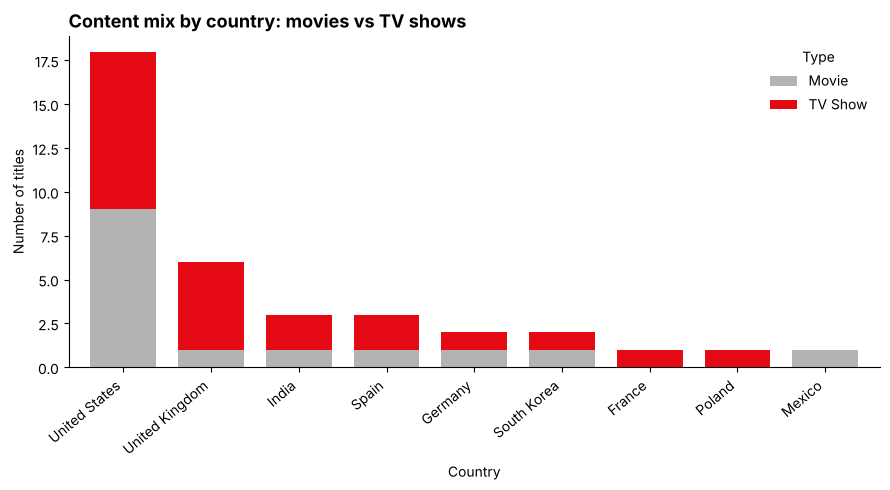

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
content_mix.plot(kind="bar", stacked=True, ax=ax, color={"Movie": LIGHT_GREY, "TV Show": NETFLIX_RED}, width=0.75)

ax.set_title("Content mix by country: movies vs TV shows", fontsize=13, weight="bold", loc="left")
ax.set_xlabel("Country")
ax.set_ylabel("Number of titles")
ax.legend(title="Type", frameon=False)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

Outside the United States, catalog content skews towards TV shows (for example the United Kingdom with five of six titles). The United States is split evenly between movies and TV shows.

### 5.4 Expansion map: content volume vs quality
Countries in the top-left (few titles, high rating) are the most promising places to add more content.

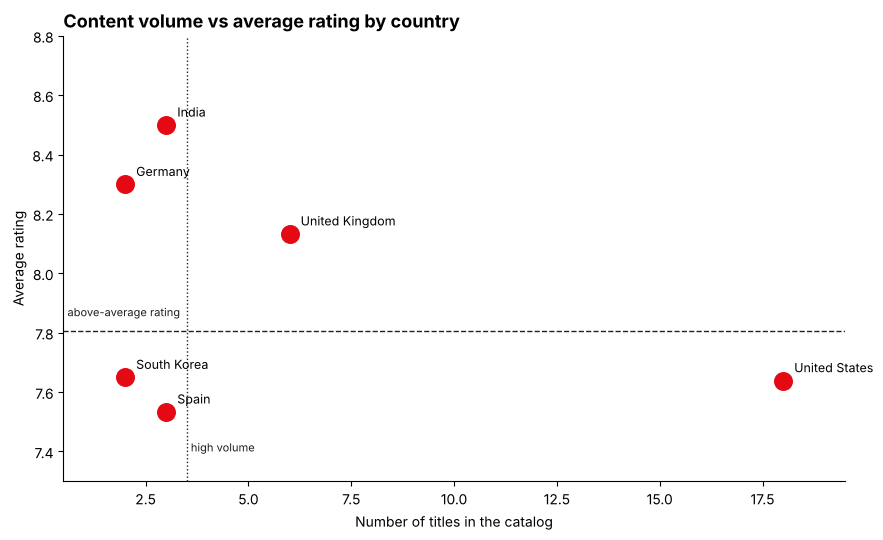

In [12]:
scatter_data = country_summary[country_summary["rated_titles"] >= MIN_RATED_TITLES]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(scatter_data["total_titles"], scatter_data["average_rating"], s=160, color=NETFLIX_RED, zorder=3)

for country, row in scatter_data.iterrows():
    ax.annotate(country, (row["total_titles"], row["average_rating"]), textcoords="offset points", xytext=(8, 6), fontsize=9)

ax.axhline(overall_average_rating, color=DARK_GREY, linestyle="--", linewidth=1)
ax.axvline(LOW_VOLUME_MAX_TITLES + 0.5, color=DARK_GREY, linestyle=":", linewidth=1)
ax.text(0.6, overall_average_rating + 0.05, "above-average rating", fontsize=8, color=DARK_GREY)
ax.text(LOW_VOLUME_MAX_TITLES + 0.6, 7.4, "high volume", fontsize=8, color=DARK_GREY)

ax.set_xlim(0.5, 19.5)
ax.set_ylim(7.3, 8.8)
ax.set_title("Content volume vs average rating by country", fontsize=13, weight="bold", loc="left")
ax.set_xlabel("Number of titles in the catalog")
ax.set_ylabel("Average rating")
plt.tight_layout()
plt.show()

## 6. Expansion analysis
A country is flagged as an **expansion candidate** when:
- it has `LOW_VOLUME_MAX_TITLES` titles or fewer (a small footprint today),
- its average rating is at or above the catalog average, and
- it has at least `MIN_RATED_TITLES` rated titles, so the rating is not based on a single title.

In [13]:
is_low_volume = country_summary["total_titles"] <= LOW_VOLUME_MAX_TITLES
is_high_quality = country_summary["average_rating"] >= overall_average_rating
has_enough_ratings = country_summary["rated_titles"] >= MIN_RATED_TITLES

expansion_candidates = country_summary[is_low_volume & is_high_quality & has_enough_ratings]
print("Expansion candidates:")
print(expansion_candidates[["total_titles", "average_rating", "share_of_titles_pct"]].round(2).to_string())

watch_list = country_summary[is_low_volume & ~country_summary.index.isin(expansion_candidates.index)]
print()
print("Low-volume countries not flagged (rating below average or too few rated titles):")
print(watch_list[["total_titles", "rated_titles", "average_rating"]].round(2).to_string())

Expansion candidates:
         total_titles  average_rating  share_of_titles_pct
country                                                   
India               3             8.5                 8.11
Germany             2             8.3                 5.41

Low-volume countries not flagged (rating below average or too few rated titles):
             total_titles  rated_titles  average_rating
country                                                
Spain                   3             3            7.53
South Korea             2             2            7.65
France                  1             1            7.50
Poland                  1             1            8.00
Mexico                  1             1            7.70


## 7. Business insights

1. **Content supply is highly concentrated.** The United States provides 18 of the 37 titles with a known country (about 49%), and the United States plus the United Kingdom together provide about 65%. The remaining seven countries contribute one to three titles each.
2. **Non-US content is rated higher in this sample.** Non-US titles average 7.97 versus 7.64 for US titles (+0.33). The United Kingdom (8.13), Germany (8.30) and India (8.50) are all above the average of 7.81 for titles with a known country, so more content volume does not mean better-rated content.
3. **India and Germany are the clearest expansion candidates.** Both have a small footprint (3 and 2 titles) but above-average ratings, and the rule in section 6 flags them. South Korea, Spain, France, Poland and Mexico have low volume too, but their ratings are below average or rest on a single title, so they belong on a watch list rather than an investment list.
4. **TV series are the strongest format outside the US.** Across the catalog, TV shows average 8.32 versus 7.02 for movies, and most non-US titles are series (for example five of six UK titles). Regional series are therefore a sensible first format for expansion.
5. **Large parts of the world are missing.** The sample contains only nine countries, with one title from Latin America (Mexico) and none from regions such as Africa or the Middle East. These gaps are possible white space, but the data cannot say how good local content there would be.

## 8. Conclusions

**Answer to the business question.** In this dataset the United States contributes the most content, followed by the United Kingdom, and together they supply about two thirds of titles with a known country. The best opportunity for expansion lies in **India and Germany**: small catalog footprints, high average ratings, and strong recent examples such as *Sacred Games*, *Delhi Crime* and *Dark*. Netflix should favor **locally produced TV series** in these markets, and keep **South Korea and Spain on a watch list** until more data supports a decision.

**Limitations**
- The file contains only 40 rows, so one title can move a country's average noticeably. Results are directional.
- `rating` is a single score per title, with no information on viewing hours or subscribers, so it measures perceived quality, not audience demand.
- Each title has one country, although many productions are co-productions.
- One title has an unknown country and one has no rating; both were handled as described in section 3.

**Next steps**
- Repeat the analysis on the full public Netflix titles dataset to confirm the pattern.
- Add viewing or subscriber data to connect quality with demand.
- Break results down by genre within the candidate countries.